In [1]:
import torch
import torch.nn as nn
import plotly.express as px
import plotly.graph_objects as go
import numpy as np

from typing import List, Tuple

## S1-1 · Activations exist for a reason.

### Claim

a model with no nonlinearity can only draw a straight boundary, so it cannot separate two interleaved/concentric rings; adding one ReLU hidden layer can.

### Build

generate ~300 noisy 2D points as two rings (inner = class 0, outer = class 1), not linearly separable.

Train (a) a single linear layer + sigmoid, (b) one ReLU hidden layer.

### Proof

plot both decision boundaries — the linear one is a straight line stuck near 55% accuracy, the ReLU one wraps the ring to ~99%. Only the activation changed. The boundary picture is the money shot.


In [2]:
# trying to construct two rings
#   1. inner ring -> this should have outer radius as 3 and inner radius as 2
#   2. outer ring -> this shoudl have outer radius as 5 and inner radius as 4

# assumption:
#   1. rings centered at (0, 0)

inner_ring_radii = torch.arange(2, 3, 0.1)
outer_ring_radii = torch.arange(4, 5, 0.1)

In [3]:
# function to generate points in a ring for inner_rad, outer_rad centered at (0, 0)
def gen_ring_points(inner_rad: int, outer_rad: int, stride: float=0.1) -> Tuple[torch.Tensor, torch.Tensor]:

    ring_x: List[torch.Tensor] = []
    ring_y: List[torch.Tensor] = []

    # create circle coordinates for very radius (from inner_rad to outer_rad)
    for rad in torch.arange(inner_rad, outer_rad, stride):
        x, y = gen_circle_points(rad)
        ring_x.append(x)
        ring_y.append(y)

    # create tensors from list for all x and y
    x = torch.cat(ring_x)
    y = torch.cat(ring_y)

    return x, y

In [4]:
# thanks claude
def plot_decision_boundary(model, train_x, train_y, x_max, title="Model Decision Boundary"):
    """Visualizes the model predictions vs training data."""
    model.eval()
    device = next(model.parameters()).device

    # 1. Create prediction grid
    x_bounds, y_bounds = (-12, 12), (-12, 12)
    stride = 0.2
    x_range = torch.linspace(x_bounds[0], x_bounds[1], int((x_bounds[1] - x_bounds[0]) / stride))
    y_range = torch.linspace(y_bounds[0], y_bounds[1], int((y_bounds[1] - y_bounds[0]) / stride))
    xy_grid = torch.cartesian_prod(x_range, y_range).to(device)

    # 2. Get predictions (normalized input)
    with torch.no_grad():
        logits = model(xy_grid / x_max)
        probs = torch.sigmoid(logits)

    # 3. Reshape for Plotly
    z_data = probs.view(len(x_range), len(y_range)).cpu().numpy().T

    fig = go.Figure()

    # Decision Boundary Contour
    fig.add_contour(
        x=x_range.numpy(), y=y_range.numpy(), z=z_data,
        colorscale="RdBu_r", zmin=0, zmax=1, opacity=0.8,
        contours=dict(start=0, end=1, size=0.1), name="Probability"
    )

    # Training Points (Rescaled back to original space)
    fig.add_scatter(
        x=(train_x[:, 0] * x_max).cpu().numpy(),
        y=(train_x[:, 1] * x_max).cpu().numpy(),
        mode="markers",
        marker=dict(color=train_y.cpu().numpy(), colorscale="RdBu_r",
                    line=dict(width=1, color="white"), size=7),
        name="Training Data"
    )

    fig.update_layout(width=700, height=700, title=title, xaxis_title="X", yaxis_title="Y")
    fig.update_yaxes(scaleanchor="x", scaleratio=1)
    fig.show()

In [5]:
def gen_circle_points(radius: float, stride: float = 0.01) -> Tuple[torch.Tensor, torch.Tensor]:

    # circle -> x^2 + y^2 = r^2
    # where x will range from -r to +r
    x = torch.arange(-radius, radius, stride)

    # value for every y corresponding to the above x
    #   (r^2 - x^2)^(0.5)
    y = torch.sqrt(radius**2 - x**2)

    x = torch.cat((x, x))
    y = torch.cat((y, -y))

    return x, y

## Generating the dataset

1. Creating two full rings

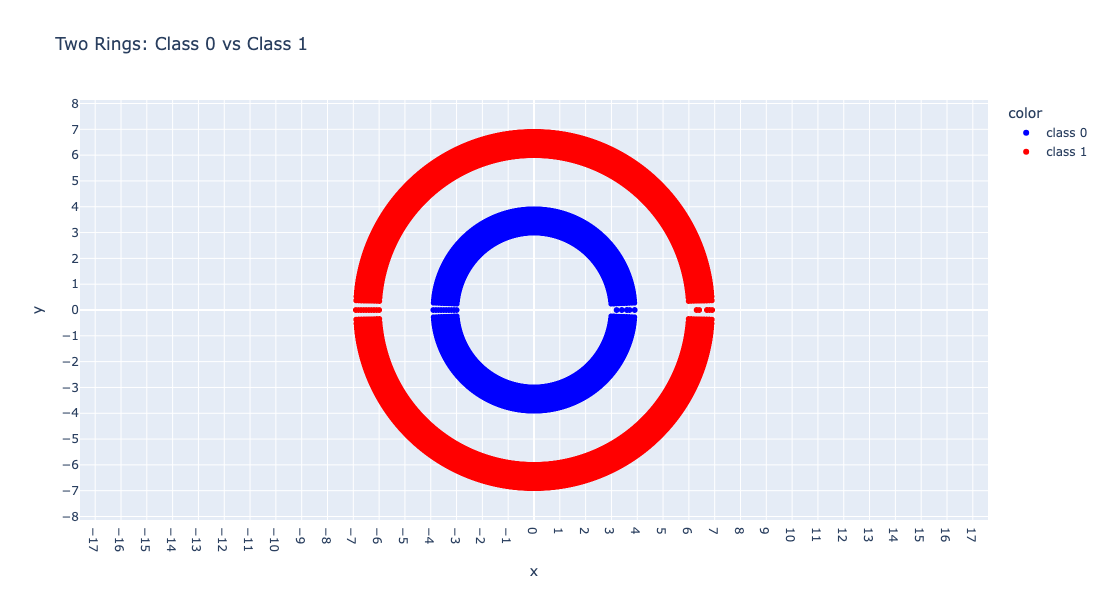

In [6]:
# Generate points for class 0 (inner ring)
x_inner, y_inner = gen_ring_points(3, 4)
# Generate points for class 1 (outer ring)
x_outer, y_outer = gen_ring_points(6, 7)

# Combine coordinates
x_all = torch.cat([x_inner, x_outer])
y_all = torch.cat([y_inner, y_outer])

# Create labels
labels = ["class 0"] * x_inner.shape[0] + ["class 1"] * x_outer.shape[0]

fig = px.scatter(
    x=x_all.numpy(),
    y=y_all.numpy(),
    range_x=[-8, 8],
    range_y=[-8, 8],
    color=labels,
    color_discrete_map={"class 0": "blue", "class 1": "red"},
    width=600,
    height=600,
    title="Two Rings: Class 0 vs Class 1"
)

# Ensure the aspect ratio is 1:1 and show all integer values on axes
fig.update_xaxes(dtick=1)
fig.update_yaxes(scaleanchor="x", scaleratio=1, dtick=1)

fig.show()

### 2. Choosing random 350 points from both the rings

1. Chosen random 350 coordinates from both the rings
2. Simple scaling by dividing with absolute maximum value

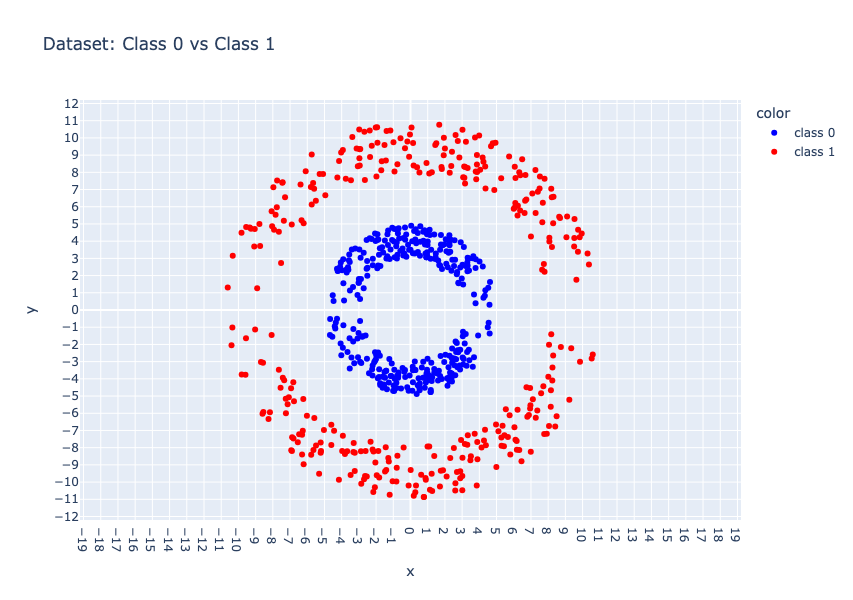

In [7]:
INNER_RING_RADIUS_BOUNDS = (3, 5)
OUTER_RING_RADIUS_BOUNDS = (8, 11)

POINTS_TO_CHOOSE = 350 # from the assignment text

# Generate points for class 0 (inner ring)
x_inner_raw, y_inner_raw = gen_ring_points(*INNER_RING_RADIUS_BOUNDS)
# Generate points for class 1 (outer ring)
x_outer_raw, y_outer_raw = gen_ring_points(*OUTER_RING_RADIUS_BOUNDS)

# Randomly selecting points
rand_inner_ind = torch.randint(0, x_inner_raw.shape[0], (POINTS_TO_CHOOSE, ))
x_inner = x_inner_raw[rand_inner_ind]
y_inner = y_inner_raw[rand_inner_ind]

rand_outer_ind = torch.randint(0, x_outer_raw.shape[0], (POINTS_TO_CHOOSE, ))
x_outer = x_outer_raw[rand_outer_ind]
y_outer = y_outer_raw[rand_outer_ind]

x_all = torch.cat((x_inner, x_outer))
y_all = torch.cat((y_inner, y_outer))

labels = ["class 0"] * x_inner.shape[0] + ["class 1"] * x_outer.shape[0]

# generated using claude
fig = px.scatter(
    x=x_all.numpy(),
    y=y_all.numpy(),
    range_x=[-12, 12],
    range_y=[-12, 12],
    color=labels,
    color_discrete_map={"class 0": "blue", "class 1": "red"},
    width=600,
    height=600,
    title="Dataset: Class 0 vs Class 1"
)

fig.update_xaxes(dtick=1)
fig.update_yaxes(scaleanchor="x", scaleratio=1, dtick=1)
fig.show()

In [8]:
# combining x=[x1, x2, x3] and y=[y1, y2, y3] to create [[x1, y1], [x2, y2], [x3, y3]]
train_x = torch.cat((
    torch.stack((x_inner, y_inner), dim=1),
    torch.stack((x_outer, y_outer), dim=1)
))

# Calculate the scalar max value for scaling
x_max = train_x.abs().max()
train_x = train_x / x_max

train_y = torch.cat((
    torch.full(x_inner.shape, 0),
    torch.full(x_outer.shape, 1)
)).float()

train_x.shape, train_y.shape

(torch.Size([700, 2]), torch.Size([700]))

## Creaing NN

Creating a simple NN with following params:
1. one hidden layer
2. since the input size is [N, 2], taking 2 neurons in the first layer
3. ~~Choosing ReLU as an actvn function~~ Not choosing any activation function

### Objective:
**Test if we are able to generalize over concentric circles using ReLU using just one layer**

In [9]:
class BasicAssNN(nn.Module):
    def __init__(self, bias: bool):
        super().__init__()
        # ek hi layer le raha hu abhi ke liye
        self.only_hidden_layer = nn.Linear(2, 1, bias=bias)
        # self.actvn = nn.ReLU()

    def forward(self, inp: torch.Tensor):
        # x = self.actvn(self.only_hidden_layer(inp))
        return self.only_hidden_layer(inp).squeeze(1)
        # return x.squeeze(1)

In [10]:
model = BasicAssNN(bias=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

train_x = train_x.to(device)
train_y = train_y.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
loss_fn = nn.BCEWithLogitsLoss()

for epoch in range(5000):
    optimizer.zero_grad()
    logits = model(train_x)
    loss = loss_fn(logits, train_y)
    loss.backward()
    optimizer.step()
    if epoch % 1000: continue
    with torch.no_grad():
        acc = ((torch.sigmoid(logits) > 0.5).float() == train_y).float().mean()
        print(f"epoch {epoch:4d} | loss {loss.item():.4f} | acc {acc.item():.3f}")

model.eval()

epoch    0 | loss 0.7047 | acc 0.540
epoch 1000 | loss 0.6914 | acc 0.537
epoch 2000 | loss 0.6914 | acc 0.537
epoch 3000 | loss 0.6914 | acc 0.537
epoch 4000 | loss 0.6914 | acc 0.537


BasicAssNN(
  (only_hidden_layer): Linear(in_features=2, out_features=1, bias=True)
)

In [11]:
x_bounds = (-10, 10)
y_bounds = (-10, 10)

stride = 0.2

num_points_x = int((x_bounds[1] - x_bounds[0]) / stride)
num_points_y = int((y_bounds[1] - y_bounds[0]) / stride)

x_range = torch.linspace(x_bounds[0], x_bounds[1], num_points_x)
y_range = torch.linspace(y_bounds[0], y_bounds[1], num_points_y)

xy = torch.cartesian_prod(x_range, y_range)

to_pred_x = xy.to(device)
with torch.no_grad():
    # Use the scalar x_max for consistent scaling
    logits = model(to_pred_x / x_max)
    probs = torch.sigmoid(logits)

print(probs.shape)

torch.Size([10000])


In [12]:
# just checking if is it really predicting 0.5 for all values

with torch.no_grad():
    # 1. Use .float() to match the model's float32 weights
    # 2. Divide by x_max because the model was trained on scaled data
    test_point = torch.tensor([0, -8]).float().unsqueeze(dim=0).to(device)
    prediction = model(test_point / x_max)
    print(f"Logit: {prediction.item():.4f}")
    print(f"Probability: {torch.sigmoid(prediction).item():.4f}")

Logit: 0.0428
Probability: 0.5107


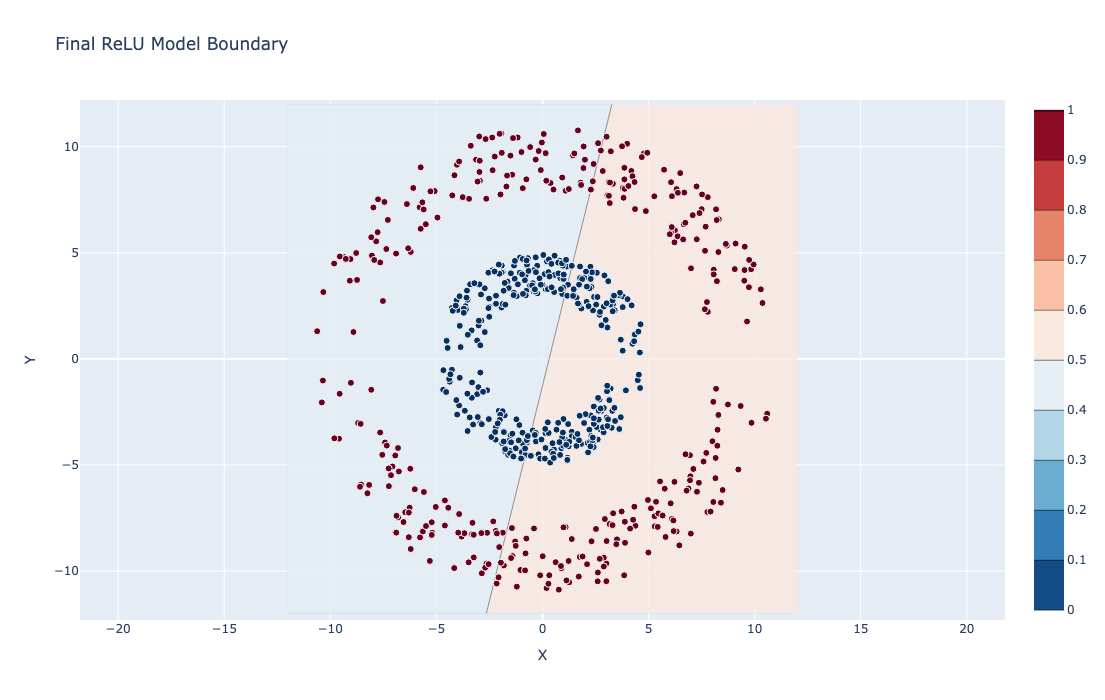

In [13]:
# Example usage for your SmartNN
plot_decision_boundary(model, train_x, train_y, x_max, title="Final ReLU Model Boundary")

### Observations

1. Does not seem to be capturing any kind of non linearity with only one layer with 2 neurons (no hidden layer)
2. Looks as good as linear regression
3. Accuracy is 0.53 as expected


## NN (with ReLU and one hidden Layer)

In [14]:
class SmartNN(nn.Module):
    def __init__(self, bias: bool, hidden: int):
        super().__init__()
        self.first_layer = nn.Linear(2, hidden, bias=bias)
        self.actvn = nn.ReLU()
        self.second_layer = nn.Linear(hidden, 1, bias=bias)

    def forward(self, inp: torch.Tensor):
        x = self.actvn(self.first_layer(inp))
        x = self.second_layer(x)
        return x.squeeze(1)

In [15]:
model = SmartNN(bias=True, hidden=32)
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

train_x = train_x.to(device)
train_y = train_y.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
loss_fn = nn.BCEWithLogitsLoss()

for epoch in range(5000):
    optimizer.zero_grad()
    logits = model(train_x)
    loss = loss_fn(logits, train_y)
    loss.backward()
    optimizer.step()
    if epoch % 1000: continue
    with torch.no_grad():
        acc = ((torch.sigmoid(logits) > 0.5).float() == train_y).float().mean()
        print(f"epoch {epoch:4d} | loss {loss.item():.4f} | acc {acc.item():.3f}")

model.eval()

epoch    0 | loss 0.6908 | acc 0.537
epoch 1000 | loss 0.0003 | acc 1.000
epoch 2000 | loss 0.0001 | acc 1.000
epoch 3000 | loss 0.0000 | acc 1.000
epoch 4000 | loss 0.0000 | acc 1.000


SmartNN(
  (first_layer): Linear(in_features=2, out_features=32, bias=True)
  (actvn): ReLU()
  (second_layer): Linear(in_features=32, out_features=1, bias=True)
)

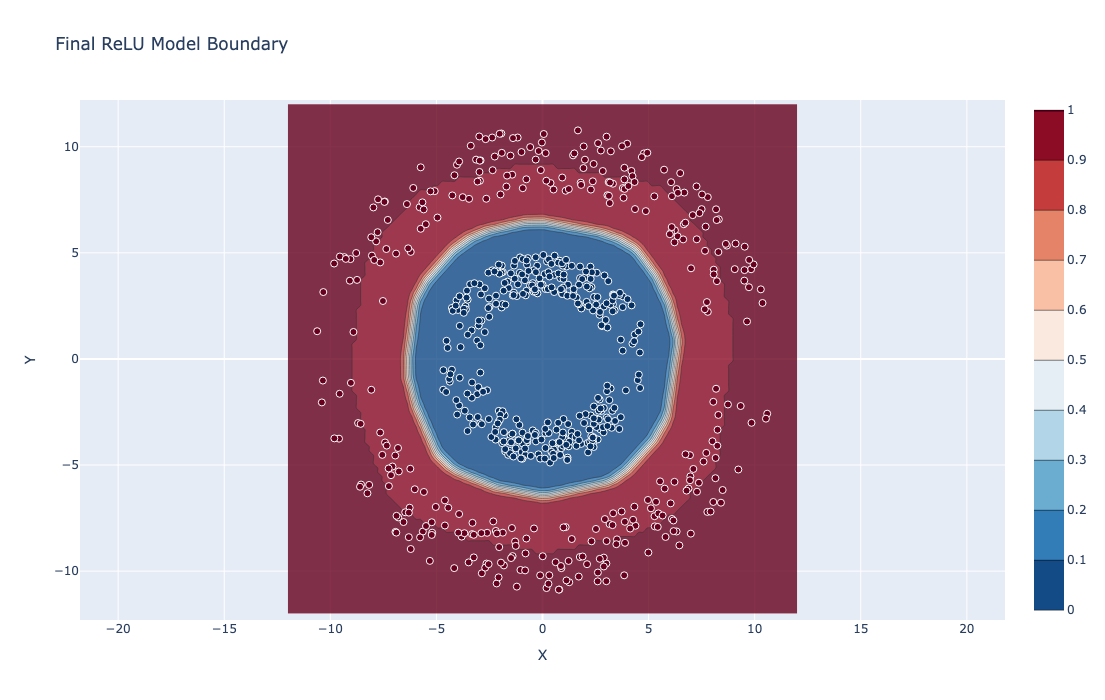

In [16]:
# Example usage for your SmartNN
plot_decision_boundary(model, train_x, train_y, x_max, title="Final ReLU Model Boundary")

## Deep Linear vs. Deep Non-Linear

### The Claim
Linear layers are just matrix multiplications. Since $W_3(W_2(W_1 x)) = (W_3 W_2 W_1)x$, stacking linear layers without activations just results in one larger matrix. They are no more powerful than a single layer.

We will compare:
1. **1-Layer Linear**
2. **5-Layer Deep Linear** (No activations)
3. **5-Layer Non-Linear** (ReLU between layers)

In [17]:
class DeepLinearNN(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        # 5 stacked linear layers with no activations
        self.net = nn.Sequential(
            nn.Linear(2, hidden, bias=False),
            nn.Linear(hidden, hidden, bias=False),
            nn.Linear(hidden, hidden, bias=False),
            nn.Linear(hidden, hidden, bias=False),
            nn.Linear(hidden, 1, bias=False)
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

class DeepReLU_NN(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        # Same 5 layers, but with ReLU in between
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

In [18]:
def train_model(model, epochs=3000):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    fn = nn.BCEWithLogitsLoss()
    for i in range(epochs):
        logits = model(train_x)
        loss = fn(logits, train_y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    acc = ((torch.sigmoid(model(train_x)) > 0.5).float() == train_y).float().mean()
    return acc.item()

print("Training Deep Linear...")
dlinear = DeepLinearNN()
dlinear_acc = train_model(dlinear)

print("Training Deep ReLU...")
drelu = DeepReLU_NN()
drelu_acc = train_model(drelu)

print(f"Deep Linear Acc: {dlinear_acc:.3f}")
print(f"Deep ReLU Acc: {drelu_acc:.3f}")

Training Deep Linear...
Training Deep ReLU...
Deep Linear Acc: 0.514
Deep ReLU Acc: 1.000


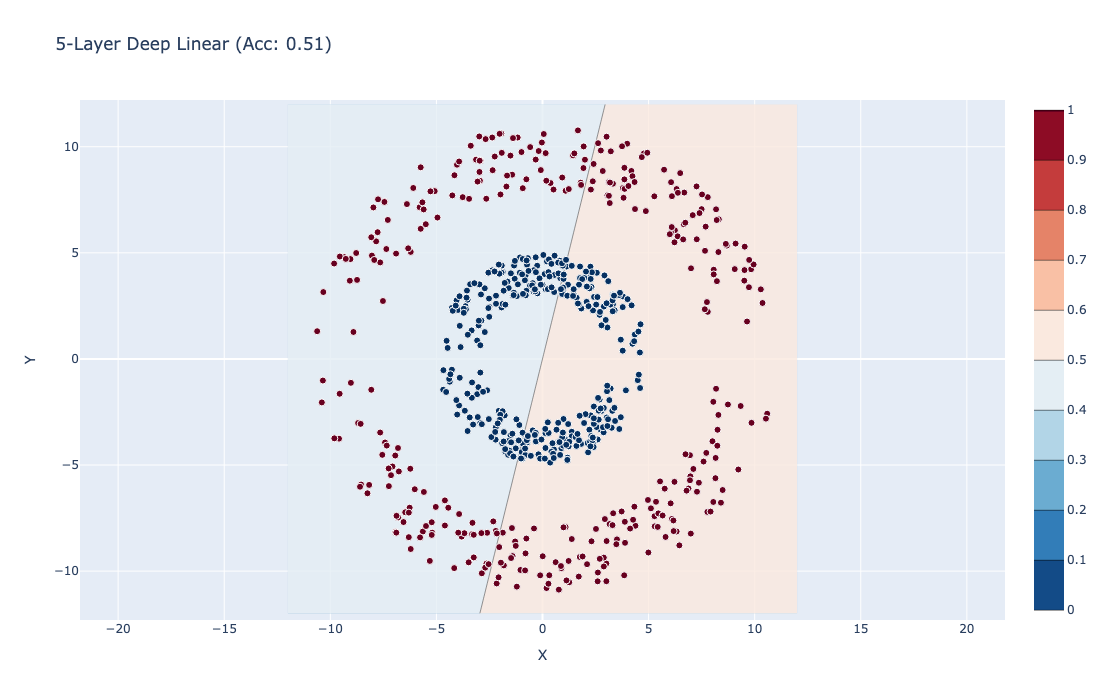

In [19]:
plot_decision_boundary(dlinear, train_x, train_y, x_max, title=f"5-Layer Deep Linear (Acc: {dlinear_acc:.2f})")

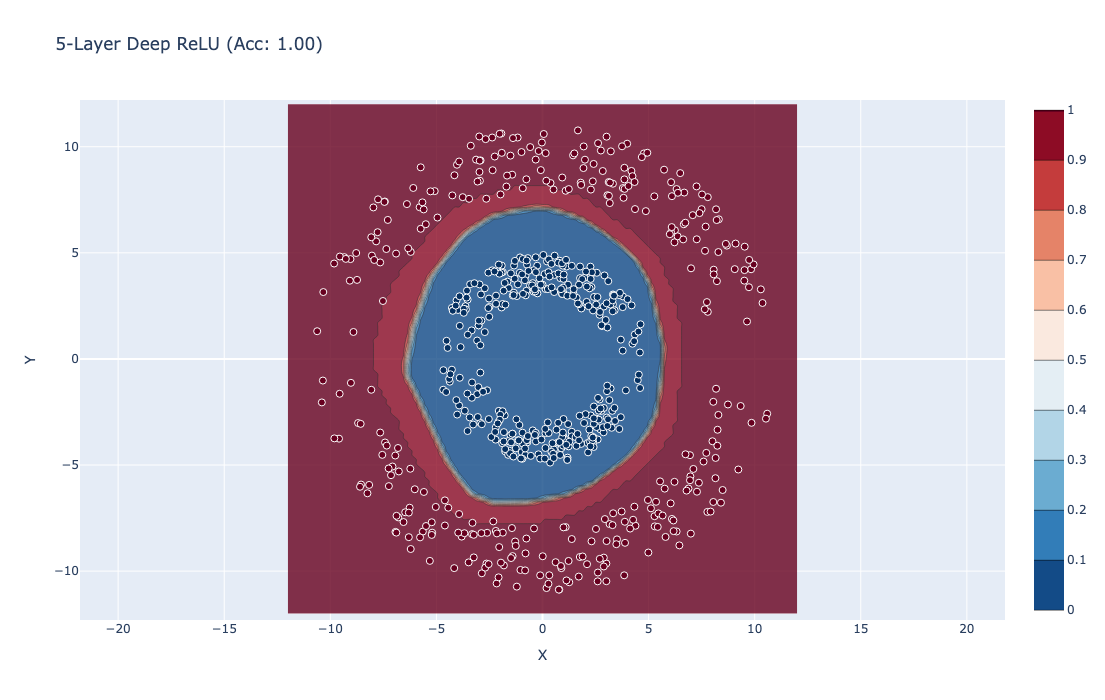

In [20]:
plot_decision_boundary(drelu, train_x, train_y, x_max, title=f"5-Layer Deep ReLU (Acc: {drelu_acc:.2f})")

### Bonus: Numerical Proof of Collapse
We will take the weight matrices of our 5-layer linear network, multiply them together manually, and show that this single product matrix produces the exact same output as the entire 5-layer network.

In [21]:
# 1. Extract weight matrices
w1 = dlinear.net[0].weight.data # (32, 2)
w2 = dlinear.net[1].weight.data # (32, 32)
w3 = dlinear.net[2].weight.data # (32, 32)
w4 = dlinear.net[3].weight.data # (32, 32)
w5 = dlinear.net[4].weight.data # (1, 32)

# 2. Collapse them: W_final = W5 @ W4 @ W3 @ W2 @ W1
# In PyTorch, weights are (out, in), so we multiply in reverse order for x @ W.T
w_collapsed = w5 @ w4 @ w3 @ w2 @ w1

# 3. Compare outputs
with torch.no_grad():
    original_output = dlinear(train_x)
    collapsed_output = (train_x @ w_collapsed.T).squeeze()

diff = torch.abs(original_output - collapsed_output).max().item()
print(f"Shape of collapsed matrix: {w_collapsed.shape}")
print(f"Max difference between 5-layer net and 1-matrix product: {diff:.8f}")

Shape of collapsed matrix: torch.Size([1, 2])
Max difference between 5-layer net and 1-matrix product: 0.00000006


## S1-3 · Embeddings learn similarity from nothing but next-token.

### Claim
trained only to predict the next token in a tiny synthetic grammar, the embedding table clusters related tokens, though similarity was never supplied.

### Build
a toy language with categories (animals: cat dog cow; fruits: apple mango; verbs: eat chase see) and templates like , so same-category tokens share next-token distributions. Train a tiny embedding→softmax next-token model.

### Proof
 project the learned embeddings to 2D and plot — same-category tokens land together; nearest neighbors are same-category. Emergent clustering = the proof.



In [22]:
grammer = [
"apple",
"cat",
"chase",
"cow",
"dog",
"eat",
"mango",
"see"
]

category_mapping = {
"cat": "animal",
"dog": "animal",
"cow": "animal",
"apple": "fruit",
"mango": "fruit",
"eat": "verb",
"chase": "verb",
"see": "verb"
}

sentences = [
"cat see mango",
"cat eat apple",
"cow chase apple",
"cat eat apple",
"cow eat mango",
"dog see mango",
"cat see mango",
"dog eat cat",
"cat eat dog",
"dog chase mango",
"cow chase apple",
"cat see dog",
"cow eat cow",
"cat see apple",
"cat eat cat",
"dog chase cow",
"cat chase dog",
"cow chase apple",
"cow see apple",
"dog chase mango",
"cow chase apple",
"cat chase mango",
"cat eat cow",
"cat see dog",
"cow chase cat",
"cat eat cow",
"cow see dog",
"dog eat cat",
"cat eat cat",
"cow eat mango",
"dog chase mango",
"cow eat cow",
"cow see mango",
"cat chase dog",
"dog eat mango",
"cow eat mango",
"cat chase apple",
"cow chase mango",
"cat chase mango",
"cat eat apple",
"cow chase apple",
"cat see mango",
"dog see mango",
"cow see apple",
"dog see cow",
"dog see dog",
"cat eat apple",
"cat see cow",
"cow eat apple",
"cow see apple"
]

In [23]:
class DummyNextWordPredictor(nn.Module):
    def __init__(self, embed_dim, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.layer = nn.Linear(2, vocab_size)

    def forward(self, x):
        return self.layer(self.embedding(x))

In [24]:
stoi = {word: ind for ind, word in enumerate(grammer)}
atoi = {ind: word for ind, word in stoi.items()}

train_x, train_y = [], []
for sentence in sentences:
    ids = [stoi[word] for word in sentence.split()]
    for ind in range(len(ids) - 1):
        train_x.append(ids[ind])
        train_y.append(ids[ind + 1])

train_x = torch.tensor(train_x, dtype=torch.long).to(device)
train_y = torch.tensor(train_y, dtype=torch.long).to(device)

train_x.shape, train_y.shape

(torch.Size([100]), torch.Size([100]))

In [25]:
model = DummyNextWordPredictor(embed_dim=2, vocab_size=len(grammer))
model.to(device)
opt = torch.optim.Adam(model.parameters(), lr=0.05)
fn = nn.CrossEntropyLoss()

for i in range(10000):
    logits = model(train_x)
    loss = fn(logits, train_y)
    opt.zero_grad()
    loss.backward()
    opt.step()

(model(train_x).argmax(dim=1) == train_y).float().mean()

tensor(0.3700)

In [26]:
model.embedding.cpu().weight

Parameter containing:
tensor([[-1.5795,  0.9478],
        [-0.6328, -3.2872],
        [ 1.0146,  2.1747],
        [-1.4941, -2.0465],
        [-2.4966, -2.3418],
        [ 1.5609,  4.4190],
        [-0.1010, -1.0963],
        [ 3.8407, -0.3098]], requires_grad=True)

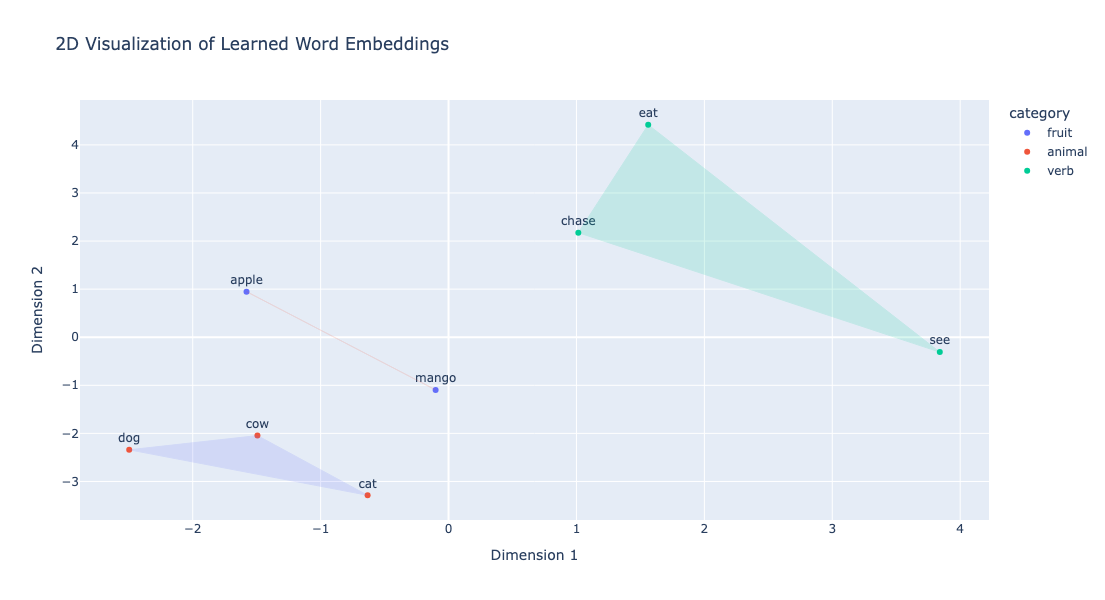

In [27]:
# thanks claude

import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from scipy.spatial import ConvexHull


weights = model.embedding.weight.detach().cpu().numpy()
cats = [category_mapping[w] for w in grammer]
plot_data = {"x": weights[:,0], "y": weights[:,1], "word": grammer, "category": cats}
fig = px.scatter(plot_data, x="x", y="y", text="word", color="category",
                 title="2D Visualization of Learned Word Embeddings",
                 labels={"x":"Dimension 1","y":"Dimension 2"}, width=800, height=600)
fig.update_traces(textposition='top center')
# draw a shaded region per category
palette = {c: col for c, col in zip(sorted(set(cats)), px.colors.qualitative.Plotly)}
for cat in sorted(set(cats)):
    pts = weights[[i for i,c in enumerate(cats) if c == cat]]
    if len(pts) >= 3:                       # hull needs 3+ points
        h = ConvexHull(pts); ring = pts[np.append(h.vertices, h.vertices[0])]
    else:                                   # 2 points -> just connect them
        ring = np.vstack([pts, pts[0]])
    fig.add_trace(go.Scatter(
        x=ring[:,0], y=ring[:,1], mode="lines", fill="toself",
        fillcolor=palette[cat], opacity=0.15, line=dict(color=palette[cat], width=1),
        name=f"{cat} region", hoverinfo="skip", showlegend=False))
fig.show()

## S1-4 · Memorization vs generalization, and data closes the gap

**Claim:** a high-capacity model on tiny data drives train loss to ~0 while held-out (test) loss stays high; growing the dataset closes the gap.

**Build:** a learnable *but noisy* 2-class task (two concentric rings + flipped labels) with a fixed held-out test set. Train the *same* over-parameterized ReLU net at train sizes **20, 200, 2000**.

**Proof:** the train/test gap is huge at 20 (train→0, test bad) and shrinks as data grows. Headline plot = generalization gap vs dataset size.


In [35]:
# --- S1-4 data: noisy two-rings classification with a fixed held-out test set ---

g = torch.Generator().manual_seed(0)

INNER_RING_RADIUS_BOUNDS = (3, 5)     # class 0 (matches S1-1/S1-2 dataset)
OUTER_RING_RADIUS_BOUNDS = (8, 11)    # class 1
NOISE = 0.10                          # fraction of TRAIN labels randomly flipped (the trap)

# dense outlines for each ring (reusing gen_ring_points defined earlier)
xi_raw, yi_raw = gen_ring_points(*INNER_RING_RADIUS_BOUNDS)
xo_raw, yo_raw = gen_ring_points(*OUTER_RING_RADIUS_BOUNDS)

# normalisation constant: outlines have UNEQUAL lengths, so cat (not stack) then max-abs
X_MAX = torch.cat([xi_raw, yi_raw, xo_raw, yo_raw]).abs().max().item()

# thanks claude for the math
def make_rings(n, noise=NOISE, seed=None):
    """Sample n noisy two-ring points by picking random indices off the dense outlines.
    Returns raw (x [n,2], y [n]); divide by X_MAX before feeding the model."""
    gen = torch.Generator().manual_seed(seed) if seed is not None else g
    n0 = n // 2; n1 = n - n0
    # class 0 = inner ring, class 1 = outer ring
    ii = torch.randint(0, xi_raw.shape[0], (n0,), generator=gen)
    io = torch.randint(0, xo_raw.shape[0], (n1,), generator=gen)
    x = torch.cat([torch.stack([xi_raw[ii], yi_raw[ii]], dim=1),
                   torch.stack([xo_raw[io], yo_raw[io]], dim=1)], dim=0)
    y = torch.cat([torch.zeros(n0), torch.ones(n1)])
    # inject label noise on the requested fraction
    flip = torch.rand(n, generator=gen) < noise
    y[flip] = 1 - y[flip]
    # shuffle
    perm = torch.randperm(n, generator=gen)
    return x[perm].to(device), y[perm].to(device)

# Fixed held-out TEST set: large and clean (noise=0) -> measures true generalization
test_x, test_y = make_rings(4000, noise=0.0, seed=999)
print("test set:", test_x.shape, test_y.shape, "| class balance:", test_y.mean().item(),
      "| X_MAX:", round(X_MAX, 3))

test set: torch.Size([4000, 2]) torch.Size([4000]) | class balance: 0.5 | X_MAX: 10.9


In [29]:
# --- over-parameterized net: deliberately too big for 20 points ---
# Wide + deep ReLU MLP. High capacity = enough room to memorize tiny data.

class OverParamNN(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)

n_params = sum(p.numel() for p in OverParamNN().parameters())
print(f"model params: {n_params:,}  (vs 20 training points -> hugely over-parameterized)")


model params: 33,537  (vs 20 training points -> hugely over-parameterized)


In [30]:
# --- train the SAME architecture at train sizes 20, 200, 2000 ---
# Only the dataset size changes. Record final train/test loss+acc and keep each
# trained model + its train set around so we can plot per-N decision boundaries.

def train_and_eval(n_train, epochs=4000, lr=0.01):
    tr_x, tr_y = make_rings(n_train, seed=n_train)   # fresh noisy train set (raw coords)
    model = OverParamNN().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    fn = nn.BCEWithLogitsLoss()

    for _ in range(epochs):
        opt.zero_grad()
        loss = fn(model(tr_x / X_MAX), tr_y)   # normalise input, matches S1-1 style
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        tr_logits, te_logits = model(tr_x / X_MAX), model(test_x / X_MAX)
        train_loss = fn(tr_logits, tr_y).item()
        test_loss  = fn(te_logits, test_y).item()
        train_acc = ((torch.sigmoid(tr_logits) > 0.5).float() == tr_y).float().mean().item()
        test_acc  = ((torch.sigmoid(te_logits) > 0.5).float() == test_y).float().mean().item()
    return dict(n=n_train, train_loss=train_loss, test_loss=test_loss,
                train_acc=train_acc, test_acc=test_acc, gap=test_loss - train_loss,
                model=model, train_x=tr_x, train_y=tr_y)

SIZES = [20, 200, 2000]
results = [train_and_eval(n) for n in SIZES]

print(f"{'N':>6} | {'train_loss':>10} {'test_loss':>10} {'gap':>8} | {'train_acc':>9} {'test_acc':>8}")
print("-" * 62)
for r in results:
    print(f"{r['n']:>6} | {r['train_loss']:>10.4f} {r['test_loss']:>10.4f} {r['gap']:>8.4f} "
          f"| {r['train_acc']:>9.3f} {r['test_acc']:>8.3f}")

     N | train_loss  test_loss      gap | train_acc test_acc
--------------------------------------------------------------
    20 |     0.0000     1.6214   1.6214 |     1.000    0.855
   200 |     0.0071     0.9677   0.9606 |     1.000    0.882
  2000 |     0.3994     0.1270  -0.2724 |     0.889    0.947


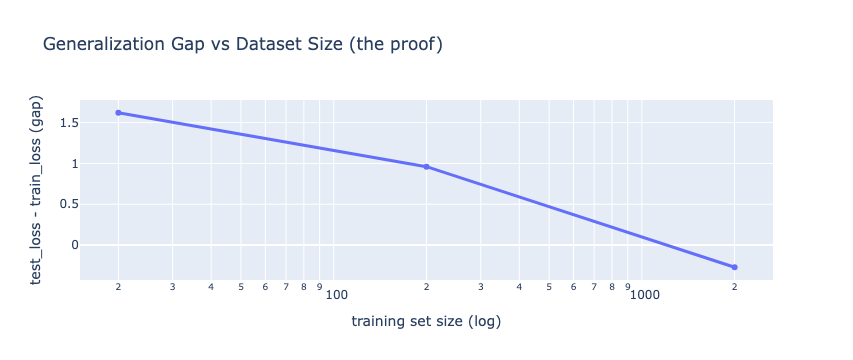

In [31]:
# --- PROOF plot 1: generalization gap vs dataset size (the headline) ---
ns   = [r["n"] for r in results]
gaps = [r["gap"] for r in results]

fig = px.line(x=ns, y=gaps, markers=True, log_x=True,
              title="Generalization Gap vs Dataset Size (the proof)",
              labels={"x": "training set size (log)", "y": "test_loss - train_loss (gap)"})
fig.update_traces(line=dict(width=3))
fig.show()


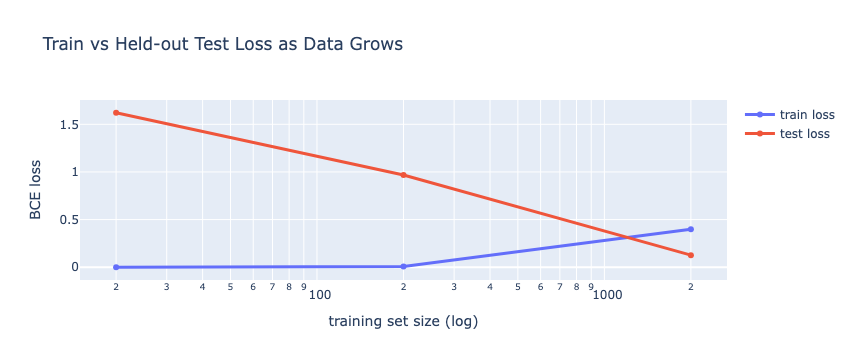

At N=20  : train_loss ~0 but test_loss high  -> the model MEMORIZED (incl. noise).
At N=2000: train and test nearly equal        -> the model GENERALIZED.
Same model, only more data. => data closes the gap. 'data is everything.'


In [32]:
# --- PROOF plot 2: train vs test loss curves (shows train stays ~0, test drops toward it) ---
fig = go.Figure()
fig.add_trace(go.Scatter(x=ns, y=[r["train_loss"] for r in results], mode="lines+markers",
                         name="train loss", line=dict(width=3)))
fig.add_trace(go.Scatter(x=ns, y=[r["test_loss"] for r in results], mode="lines+markers",
                         name="test loss", line=dict(width=3)))
fig.update_layout(title="Train vs Held-out Test Loss as Data Grows",
                  xaxis_title="training set size (log)", yaxis_title="BCE loss",
                  xaxis_type="log")
fig.show()

# Interpretation
print("At N=20  : train_loss ~0 but test_loss high  -> the model MEMORIZED (incl. noise).")
print("At N=2000: train and test nearly equal        -> the model GENERALIZED.")
print("Same model, only more data. => data closes the gap. 'data is everything.'")


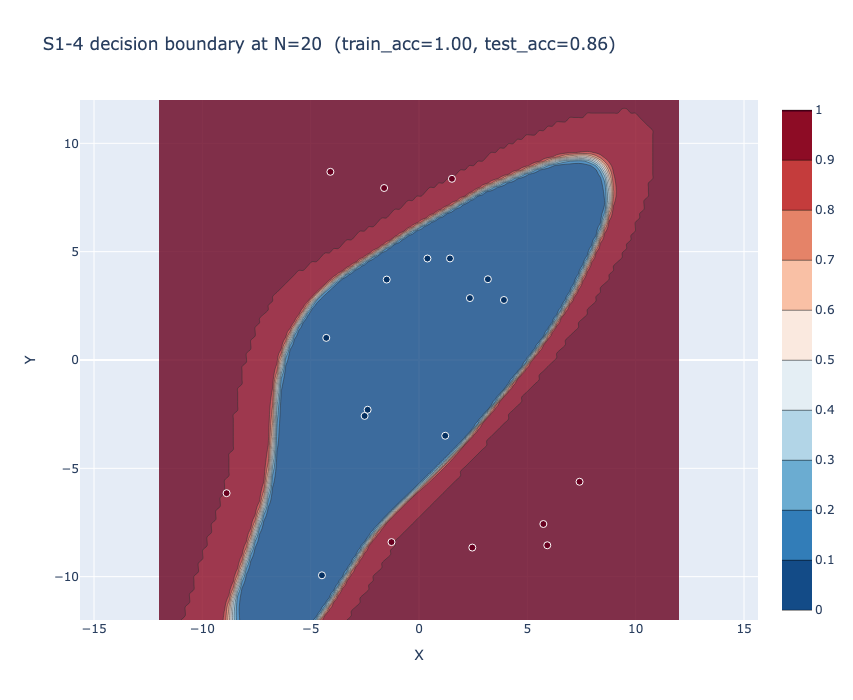

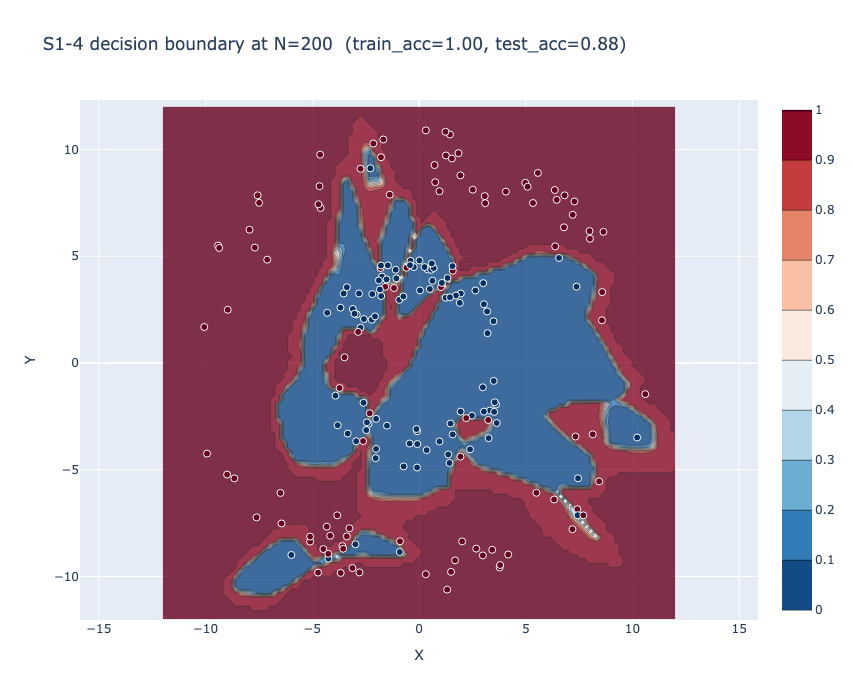

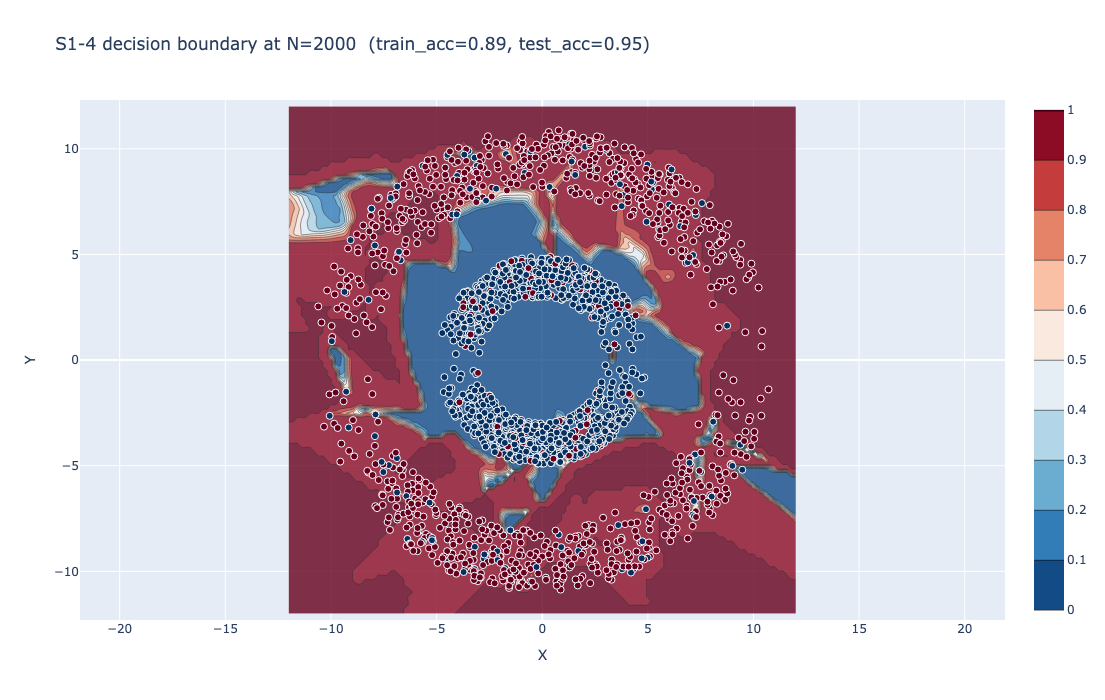

In [33]:
# --- PROOF plot 3: per-N decision boundaries (reuses plot_decision_boundary from S1-1) ---
# At N=20 the boundary is jagged / forms islands around individual points (memorized
# the noise); as N grows it relaxes into the true clean ring (generalization).
# plot_decision_boundary expects NORMALISED train_x (it rescales by x_max internally),
# so we pass train_x / X_MAX.
for r in results:
    plot_decision_boundary(
        r["model"], r["train_x"] / X_MAX, r["train_y"], X_MAX,
        title=f"S1-4 decision boundary at N={r['n']}  "
              f"(train_acc={r['train_acc']:.2f}, test_acc={r['test_acc']:.2f})",
    )

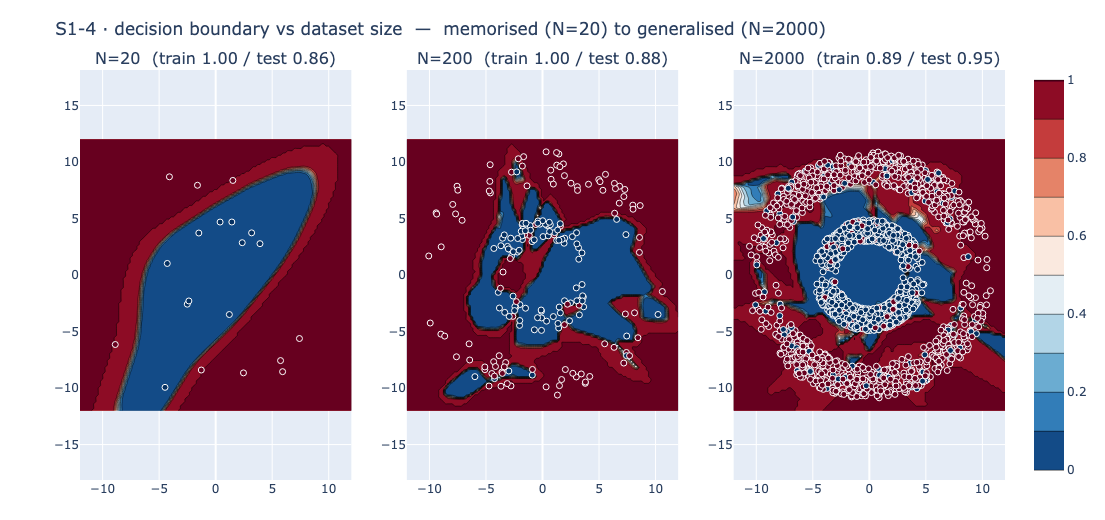

In [37]:
# --- PROOF plot 3b: ALL per-N decision boundaries in ONE grid (easier to screenshot) ---
# Same trained models as above (from `results`), drawn side by side so the boundary's
# journey from memorised islands (N=20) to a clean ring (N=2000) reads in one glance.
from plotly.subplots import make_subplots

_titles = [f"N={r['n']}  (train {r['train_acc']:.2f} / test {r['test_acc']:.2f})" for r in results]
gridfig = make_subplots(rows=1, cols=3, subplot_titles=_titles, horizontal_spacing=0.06)

_xr = torch.linspace(-12, 12, 120)
_yr = torch.linspace(-12, 12, 120)
_grid = torch.cartesian_prod(_xr, _yr)

for _col, r in enumerate(results, start=1):
    m = r["model"]; m.eval()
    with torch.no_grad():
        _z = torch.sigmoid(m(_grid / X_MAX)).view(len(_xr), len(_yr)).cpu().numpy().T
    gridfig.add_contour(x=_xr.numpy(), y=_yr.numpy(), z=_z, colorscale="RdBu_r",
                        zmin=0, zmax=1, showscale=(_col == 3),
                        contours=dict(start=0, end=1, size=0.1), row=1, col=_col)
    gridfig.add_scatter(x=r["train_x"][:, 0].cpu().numpy(), y=r["train_x"][:, 1].cpu().numpy(),
                        mode="markers", showlegend=False,
                        marker=dict(color=r["train_y"].cpu().numpy(), colorscale="RdBu_r",
                                    line=dict(width=1, color="white"), size=6),
                        row=1, col=_col)

gridfig.update_layout(width=1500, height=520, margin=dict(t=70, b=40),
                      title="S1-4 · decision boundary vs dataset size  —  memorised (N=20) to generalised (N=2000)")
gridfig.update_yaxes(scaleanchor="x", scaleratio=1)
gridfig.update_xaxes(range=[-12, 12]); gridfig.update_yaxes(range=[-12, 12])
gridfig.show()